#### Import Necessary Libraries

In [40]:
#Data manipulation
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt

# Preprocessing
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
train_test_split,
RandomizedSearchCV,
TimeSeriesSplit,
cross_val_score
)

# K-mean clustering
from sklearn.cluster import KMeans

# Classifier
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn.metrics import (precision_recall_curve,
roc_curve,
RocCurveDisplay,
ConfusionMatrixDisplay
)

from sklearn.metrics import (accuracy_score,
f1_score,
recall_score,
precision_score,
roc_auc_score,
auc
)

from sklearn.metrics import (classification_report,
confusion_matrix
)

# Import tensorflow and keras
import tensorflow
import keras 

# Import pandas-ta
import pandas_ta as ta

#### Retrieving the Historical Price

In [41]:
files = ["CMA.csv", "HML.csv", "MKT.csv", "Return.csv", "RMW.csv", "SMB.csv", "UMD.csv"]
tickers = ["cma", "hml", "mkt", "Return", "rmw", "smb", "umd"]


data = pd.DataFrame()

# Load files and concatenate DataFrames
for i, file in enumerate(files):
    df = pd.read_csv(file, index_col=0, parse_dates=True)
    df.columns = [f"{col}_{tickers[i]}" for col in df.columns]  # Add suffixes
    data = pd.concat([data, df], axis=1)
    
# ALso save each original ticker data into a single dataframe for later calculation of technical indicators
for ticker in tickers:
    globals()[ticker] = pd.read_csv(ticker + ".csv", index_col=0, parse_dates=True)
    
data

,close_cma,close_hml,close_mkt,close_Return,close_rmw,close_smb,close_umd
date,,,,,,,
2/1/2014,0.005573,0.016541,-0.053221,-0.047340,0.002402,0.012353,-0.013186
3/1/2014,-0.001040,0.016333,-0.005285,0.007205,-0.006938,-0.007504,-0.001181
6/1/2014,-0.000661,-0.008409,0.005480,0.006666,-0.008829,-0.018920,0.011955
7/1/2014,-0.006445,-0.015975,0.026072,0.020988,0.007696,-0.004548,0.005953
8/1/2014,0.003194,-0.005862,-0.003476,-0.003139,0.003944,-0.003521,-0.001385
...,...,...,...,...,...,...,...
24/4/2024,-0.006187,-0.010302,0.003068,-0.002653,0.003958,-0.005578,0.005125
25/4/2024,-0.001990,-0.004040,0.002615,0.004100,0.002175,0.003942,0.002862
26/4/2024,-0.007605,0.007793,-0.003100,-0.003670,0.004133,0.002374,0.000403


## Exploratory Data Analysis

In [42]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
close_cma,2507.0,0.000213,0.005698,-0.047966,-0.002797,0.000223,0.003252,0.046206
close_hml,2507.0,0.000146,0.005852,-0.022967,-0.003359,-0.000034,0.003567,0.028299
close_mkt,2507.0,0.000142,0.009317,-0.108409,-0.004124,0.000333,0.004660,0.082148
close_Return,2507.0,-0.000699,0.007273,-0.058480,-0.004498,-0.000604,0.003069,0.119884
close_rmw,2507.0,0.000032,0.004787,-0.026652,-0.002879,0.000003,0.002987,0.025009
close_smb,2507.0,0.000083,0.006097,-0.052801,-0.003004,0.000281,0.003631,0.038111
close_umd,2507.0,0.000284,0.007424,-0.100241,-0.003617,0.000217,0.004275,0.057125


In [43]:
# check for missing values
data.isnull().sum()

close_cma       0
close_hml       0
close_mkt       0
close_Return    0
close_rmw       0
close_smb       0
close_umd       0
dtype: int64

## Data Cleaning

In [44]:
# check for missing values
data.isnull().sum()

close_cma       0
close_hml       0
close_mkt       0
close_Return    0
close_rmw       0
close_smb       0
close_umd       0
dtype: int64

## Data Transformation

In [45]:
# Define the SMA periods
sma_periods = [5, 10, 20, 50, 100, 200]

# Loop through each ticker and calculate SMA for each period
for ticker in tickers:
    # Identify the column that contains the close prices (assuming the column name is 'close' followed by the ticker)
    close_col = f"close_{ticker}"
    
    # Check if the column exists in the data DataFrame
    if close_col in data.columns:
        for period in sma_periods:
            # Calculate SMA
            sma_col = f"SMA_{period}_{ticker}"
            sma_series = ta.sma(data[close_col], length=period)
            
            # Add SMA to the DataFrame with appropriate name
            data[sma_col] = sma_series
    else:
        print(f"Column {close_col} does not exist in the DataFrame.")

print(data)

           close_cma  close_hml  close_mkt  close_Return  close_rmw  \
date                                                                  
2/1/2014    0.005573   0.016541  -0.053221     -0.047340   0.002402   
3/1/2014   -0.001040   0.016333  -0.005285      0.007205  -0.006938   
6/1/2014   -0.000661  -0.008409   0.005480      0.006666  -0.008829   
7/1/2014   -0.006445  -0.015975   0.026072      0.020988   0.007696   
8/1/2014    0.003194  -0.005862  -0.003476     -0.003139   0.003944   
...              ...        ...        ...           ...        ...   
24/4/2024  -0.006187  -0.010302   0.003068     -0.002653   0.003958   
25/4/2024  -0.001990  -0.004040   0.002615      0.004100   0.002175   
26/4/2024  -0.007605   0.007793  -0.003100     -0.003670   0.004133   
29/4/2024   0.008354   0.010206   0.001667     -0.001869  -0.006341   
30/4/2024   0.003656  -0.006148   0.004770      0.002389  -0.000367   

           close_smb  close_umd  SMA_5_cma  SMA_10_cma  SMA_20_cma  ...  \
d

In [46]:
# Define the EMA periods
ema_periods = [5, 8, 10, 12, 25, 26, 50, 200]

# Loop through each ticker and calculate EMA for each period
for ticker in tickers:
    # Identify the column that contains the close prices (assuming the column name is 'close' followed by the ticker)
    close_col = f"close_{ticker}"
    
    # Check if the column exists in the data DataFrame
    if close_col in data.columns:
        for period in ema_periods:
            # Calculate EMA
            ema_col = f"EMA_{period}_{ticker}"
            ema_series = ta.ema(data[close_col], length=period)
            
            # Add EMA to the DataFrame with appropriate name
            data[ema_col] = ema_series
    else:
        print(f"Column {close_col} does not exist in the DataFrame.")

print(data) 

           close_cma  close_hml  close_mkt  close_Return  close_rmw  \
date                                                                  
2/1/2014    0.005573   0.016541  -0.053221     -0.047340   0.002402   
3/1/2014   -0.001040   0.016333  -0.005285      0.007205  -0.006938   
6/1/2014   -0.000661  -0.008409   0.005480      0.006666  -0.008829   
7/1/2014   -0.006445  -0.015975   0.026072      0.020988   0.007696   
8/1/2014    0.003194  -0.005862  -0.003476     -0.003139   0.003944   
...              ...        ...        ...           ...        ...   
24/4/2024  -0.006187  -0.010302   0.003068     -0.002653   0.003958   
25/4/2024  -0.001990  -0.004040   0.002615      0.004100   0.002175   
26/4/2024  -0.007605   0.007793  -0.003100     -0.003670   0.004133   
29/4/2024   0.008354   0.010206   0.001667     -0.001869  -0.006341   
30/4/2024   0.003656  -0.006148   0.004770      0.002389  -0.000367   

           close_smb  close_umd  SMA_5_cma  SMA_10_cma  SMA_20_cma  ...  \
d

In [47]:
# Define the RSI periods
rsi_periods = [5, 9, 14, 30]

# Loop through each ticker and calculate RSI for each period
for ticker in tickers:
    # Identify the column that contains the close prices (assuming the column name is 'close' followed by the ticker)
    close_col = f"close_{ticker}"
    
    # Check if the column exists in the data DataFrame
    if close_col in data.columns:
        for period in rsi_periods:
            # Calculate RSI
            rsi_col = f"RSI_{period}_{ticker}"
            rsi_series = ta.rsi(data[close_col], length=period)
            
            # Add RSI to the DataFrame with appropriate name
            data[rsi_col] = rsi_series
    else:
        print(f"Column {close_col} does not exist in the DataFrame.")

print(data)

           close_cma  close_hml  close_mkt  close_Return  close_rmw  \
date                                                                  
2/1/2014    0.005573   0.016541  -0.053221     -0.047340   0.002402   
3/1/2014   -0.001040   0.016333  -0.005285      0.007205  -0.006938   
6/1/2014   -0.000661  -0.008409   0.005480      0.006666  -0.008829   
7/1/2014   -0.006445  -0.015975   0.026072      0.020988   0.007696   
8/1/2014    0.003194  -0.005862  -0.003476     -0.003139   0.003944   
...              ...        ...        ...           ...        ...   
24/4/2024  -0.006187  -0.010302   0.003068     -0.002653   0.003958   
25/4/2024  -0.001990  -0.004040   0.002615      0.004100   0.002175   
26/4/2024  -0.007605   0.007793  -0.003100     -0.003670   0.004133   
29/4/2024   0.008354   0.010206   0.001667     -0.001869  -0.006341   
30/4/2024   0.003656  -0.006148   0.004770      0.002389  -0.000367   

           close_smb  close_umd  SMA_5_cma  SMA_10_cma  SMA_20_cma  ...  \
d

C:\Users\tonfo\AppData\Local\Temp\ipykernel_26232\342043520.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[rsi_col] = rsi_series
C:\Users\tonfo\AppData\Local\Temp\ipykernel_26232\342043520.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[rsi_col] = rsi_series
C:\Users\tonfo\AppData\Local\Temp\ipykernel_26232\342043520.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once usi

In [48]:
# Define the Bollinger Bands parameters
bb_params = [
    (10, 1.5),
    (20, 2),
    (50, 2.5)
]

# Loop through each ticker and calculate Bollinger Bands for each parameter set
for ticker in tickers:
    # Identify the column that contains the close prices (assuming the column name is 'close' followed by the ticker)
    close_col = f"close_{ticker}"
    
    # Check if the column exists in the data DataFrame
    if close_col in data.columns:
        for period, std_dev in bb_params:
            # Calculate Bollinger Bands
            bb = ta.bbands(data[close_col], length=period, std=std_dev)
            
            # Extract the Bollinger Bands components from the returned DataFrame
            bb_upper_col = bb.columns[0]
            bb_middle_col = bb.columns[1]
            bb_lower_col = bb.columns[2]
            
            bb_upper = bb[bb_upper_col]
            bb_middle = bb[bb_middle_col]
            bb_lower = bb[bb_lower_col]
            
            # Add Bollinger Bands components to the DataFrame with appropriate names
            data[f"BB_upper_{period}_{std_dev}_{ticker}"] = bb_upper
            data[f"BB_middle_{period}_{std_dev}_{ticker}"] = bb_middle
            data[f"BB_lower_{period}_{std_dev}_{ticker}"] = bb_lower
    else:
        print(f"Column {close_col} does not exist in the DataFrame.")

print(data)

           close_cma  close_hml  close_mkt  close_Return  close_rmw  \
date                                                                  
2/1/2014    0.005573   0.016541  -0.053221     -0.047340   0.002402   
3/1/2014   -0.001040   0.016333  -0.005285      0.007205  -0.006938   
6/1/2014   -0.000661  -0.008409   0.005480      0.006666  -0.008829   
7/1/2014   -0.006445  -0.015975   0.026072      0.020988   0.007696   
8/1/2014    0.003194  -0.005862  -0.003476     -0.003139   0.003944   
...              ...        ...        ...           ...        ...   
24/4/2024  -0.006187  -0.010302   0.003068     -0.002653   0.003958   
25/4/2024  -0.001990  -0.004040   0.002615      0.004100   0.002175   
26/4/2024  -0.007605   0.007793  -0.003100     -0.003670   0.004133   
29/4/2024   0.008354   0.010206   0.001667     -0.001869  -0.006341   
30/4/2024   0.003656  -0.006148   0.004770      0.002389  -0.000367   

           close_smb  close_umd  SMA_5_cma  SMA_10_cma  SMA_20_cma  ...  \
d

C:\Users\tonfo\AppData\Local\Temp\ipykernel_26232\1339690556.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"BB_upper_{period}_{std_dev}_{ticker}"] = bb_upper
C:\Users\tonfo\AppData\Local\Temp\ipykernel_26232\1339690556.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"BB_middle_{period}_{std_dev}_{ticker}"] = bb_middle
C:\Users\tonfo\AppData\Local\Temp\ipykernel_26232\1339690556.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, whic

In [49]:
# Save the matrix
data.to_csv('indicators_data.csv')

### Label Definition

In [64]:
# Copy the feature DataFrame
df = data.copy()

# Define the 6-month (approximately 126 trading days) forward total return threshold
forward_period = 126  # You can adjust this based on your data frequency
threshold = 1.05

# Calculate the 6-month forward return
df['Forward_Return'] = (df['close_Return'].rolling(window = 126).sum())

# Define the target based on the 6-month forward return threshold
df['Target'] = np.where(df['Forward_Return'] > threshold, 1, 0)

# Drop the rows where there is no label (i.e., where the forward return cannot be calculated)
df = df.iloc[:-1]

# Drop the rows with NaN values
df.dropna(inplace=True)

# Define feature matrix X and target vector y
X = df.drop(['Target', 'Forward_Return'], axis=1)
y = df['Target']

# Print the resulting DataFrame (optional)
print(df)

            close_cma  close_hml  close_mkt  close_Return  close_rmw  \
date                                                                   
24/10/2014  -0.003497  -0.005334   0.005108      0.001248  -0.009538   
27/10/2014  -0.008187  -0.006843   0.005166      0.003371  -0.003253   
28/10/2014  -0.004121   0.004206   0.005524      0.004822   0.003521   
29/10/2014   0.000308  -0.001983   0.004195     -0.001176  -0.005815   
30/10/2014   0.001639   0.000025   0.001641     -0.000326  -0.002277   
...               ...        ...        ...           ...        ...   
23/4/2024    0.000173   0.002385   0.006514      0.002926  -0.001477   
24/4/2024   -0.006187  -0.010302   0.003068     -0.002653   0.003958   
25/4/2024   -0.001990  -0.004040   0.002615      0.004100   0.002175   
26/4/2024   -0.007605   0.007793  -0.003100     -0.003670   0.004133   
29/4/2024    0.008354   0.010206   0.001667     -0.001869  -0.006341   

            close_smb  close_umd  SMA_5_cma  SMA_10_cma  SMA_20

In [51]:
df.head

<bound method NDFrame.head of             close_cma  close_hml  close_mkt  close_Return  close_rmw  \
date                                                                   
24/10/2014  -0.003497  -0.005334   0.005108      0.001248  -0.009538   
27/10/2014  -0.008187  -0.006843   0.005166      0.003371  -0.003253   
28/10/2014  -0.004121   0.004206   0.005524      0.004822   0.003521   
29/10/2014   0.000308  -0.001983   0.004195     -0.001176  -0.005815   
30/10/2014   0.001639   0.000025   0.001641     -0.000326  -0.002277   
...               ...        ...        ...           ...        ...   
23/4/2024    0.000173   0.002385   0.006514      0.002926  -0.001477   
24/4/2024   -0.006187  -0.010302   0.003068     -0.002653   0.003958   
25/4/2024   -0.001990  -0.004040   0.002615      0.004100   0.002175   
26/4/2024   -0.007605   0.007793  -0.003100     -0.003670   0.004133   
29/4/2024    0.008354   0.010206   0.001667     -0.001869  -0.006341   

            close_smb  close_umd 

In [52]:
X_train,X_test = X[0:600],X[715:716]
y_train, y_test= y[0:600],y[715:716]

# Output the training and test data size
print(f"Train and Test Size {len(X_train)}, {len(X_test)}")

Train and Test Size 600, 1


### Data Scaling

In [53]:
# Use StandardScaler
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), index=X_train.index, columns=X_train.columns)

# Apply the scaler to the test set
X_test_scaled = pd.DataFrame(scaler.transform(X_test), index=X_test.index, columns=X_test.columns)

X_train_scaled.describe()

,close_cma,close_hml,close_mkt,close_Return,close_rmw,close_smb,close_umd,SMA_5_cma,SMA_10_cma,SMA_20_cma,...,BB_lower_50_2.5_smb,BB_upper_10_1.5_umd,BB_middle_10_1.5_umd,BB_lower_10_1.5_umd,BB_upper_20_2_umd,BB_middle_20_2_umd,BB_lower_20_2_umd,BB_upper_50_2.5_umd,BB_middle_50_2.5_umd,BB_lower_50_2.5_umd
count,6.000000e+02,6.000000e+02,6.000000e+02,600.000000,6.000000e+02,6.000000e+02,6.000000e+02,600.000000,6.000000e+02,600.000000,...,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02
mean,-1.184238e-17,1.184238e-17,1.776357e-17,0.000000,-5.921189e-18,4.440892e-18,-1.184238e-17,0.000000,2.368476e-17,0.000000,...,3.552714e-16,-4.736952e-16,1.184238e-17,3.197442e-16,3.552714e-16,-5.921189e-17,-4.500104e-16,-3.552714e-16,-1.184238e-17,-6.394885e-16
std,1.000834e+00,1.000834e+00,1.000834e+00,1.000834,1.000834e+00,1.000834e+00,1.000834e+00,1.000834,1.000834e+00,1.000834,...,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00
min,-3.830998e+00,-3.744837e+00,-5.547969e+00,-3.710519,-3.473065e+00,-4.395884e+00,-3.836412e+00,-3.632934,-2.958408e+00,-2.972436,...,-1.755836e+00,-3.667220e+00,-2.934997e+00,-2.271537e+00,-2.848175e+00,-2.636896e+00,-1.859261e+00,-2.050533e+00,-1.931984e+00,-1.726443e+00
25%,-6.098149e-01,-5.885397e-01,-5.193783e-01,-0.627551,-5.994651e-01,-5.445930e-01,-5.965485e-01,-0.617386,-6.333010e-01,-0.631806,...,-8.105412e-01,-4.806752e-01,-6.647557e-01,-6.616556e-01,-6.592410e-01,-6.680642e-01,-7.402768e-01,-7.676919e-01,-7.131993e-01,-7.592326e-01
50%,1.794492e-02,-7.057521e-02,1.966485e-02,0.051379,1.536491e-02,6.351803e-02,-1.907706e-02,-0.018532,-1.048313e-01,-0.093434,...,-1.286406e-01,9.362838e-02,7.881500e-02,-8.527781e-02,1.475321e-01,-5.514035e-02,-2.862338e-01,-6.579045e-02,-1.183715e-01,-6.683969e-02
75%,6.164193e-01,5.804310e-01,5.703754e-01,0.629432,6.797075e-01,6.217119e-01,6.295926e-01,0.592748,6.086922e-01,0.625946,...,5.742390e-01,7.288726e-01,6.298807e-01,5.711800e-01,7.444950e-01,5.880216e-01,6.438893e-01,8.583634e-01,5.289016e-01,6.298983e-01
max,3.416566e+00,4.334948e+00,5.369493e+00,3.053162,3.996950e+00,4.046302e+00,4.350155e+00,4.007078,3.157320e+00,2.835884,...,2.339577e+00,1.861306e+00,3.339288e+00,3.822377e+00,1.671799e+00,3.569474e+00,3.301484e+00,1.867816e+00,3.336208e+00,3.040849e+00


In [54]:
# Store the scaled data in the original variables
X_train = X_train_scaled
X_test = X_test_scaled

### K-means Clustering

In [55]:
# K-mean clustering
inertia = []

K = range(1, 50)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=999)
    kmeans.fit(X_train.T)
    inertia.append(kmeans.inertia_)

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\clus

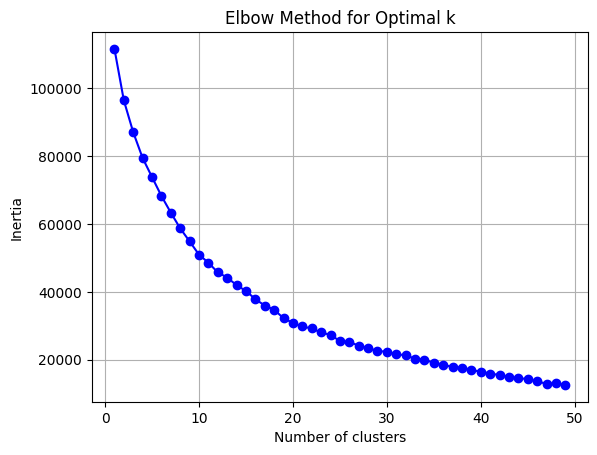

In [56]:
# Elbow plot
plt.plot(K, inertia, 'bo-')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

In [57]:
# Apply K-means with K=13
kmeans = KMeans(n_clusters=9, random_state=999)
kmeans.fit(X_train.T)

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


KMeans(n_clusters=9, random_state=999)

In [58]:
# Centroids of the clusters
centroids = kmeans.cluster_centers_

# Extract the numerical values from the X_train DataFrame
df = X_train.T
a = df.values

# Find the features that are closest to the centroids
distances = np.linalg.norm(a - centroids[:, np.newaxis], axis=2)
closest_centroid_indices = np.argmin(distances, axis=1)
closest_feat = df.iloc[closest_centroid_indices]

# Display the selected indicators
closest_feat

date,24/10/2014,27/10/2014,28/10/2014,29/10/2014,30/10/2014,31/10/2014,3/11/2014,4/11/2014,5/11/2014,6/11/2014,...,28/3/2017,29/3/2017,30/3/2017,31/3/2017,3/4/2017,4/4/2017,5/4/2017,7/4/2017,10/4/2017,11/4/2017
RSI_14_Return,0.580224,0.972988,1.249807,-0.056315,0.127339,1.909612,-1.316046,0.310116,-0.839569,0.108489,...,0.567442,-0.198876,0.628753,-1.423917,0.412009,0.567231,-0.496529,0.585145,-0.017275,-0.009343
EMA_25_smb,1.443031,1.876135,1.486654,1.533280,1.375319,0.811305,0.530348,0.312354,0.708185,0.976462,...,-0.552839,-0.444444,-0.408102,-0.142348,-0.288360,-0.376599,-0.580915,-0.888394,-1.011588,-0.883215
EMA_25_rmw,-1.404683,-1.580127,-1.176724,-1.583554,-1.663844,-2.273969,-1.904399,-1.448585,-1.609362,-1.270820,...,0.129307,0.155211,0.669806,0.192336,-0.087508,-0.202641,0.052354,0.056264,0.122373,-0.152897
EMA_25_Return,-0.929200,-0.563199,-0.121059,-0.143930,-0.103940,0.559667,0.034221,0.156509,-0.185619,-0.144007,...,0.919251,0.863923,1.018459,0.635207,0.747006,0.891430,0.760912,0.907943,0.900874,0.896158
EMA_200_hml,0.265265,0.048673,0.162973,0.091995,0.081483,0.087201,0.199164,0.007635,0.189550,0.354155,...,1.389080,1.339392,1.232255,1.257782,1.133124,1.033985,1.168262,1.150927,1.147464,1.193220
EMA_25_umd,0.879681,0.920205,1.015604,1.139080,0.810790,0.398324,0.208474,-0.040861,-0.092862,-0.585513,...,-0.735571,-0.653530,-0.776345,-1.067805,-0.524790,-0.457946,-0.763735,-0.696758,-0.705215,-0.614353
BB_lower_20_2_Return,-0.394500,-0.506810,-0.336641,-0.352415,-0.328296,0.015261,-0.021820,-0.586552,-0.566572,-1.003958,...,-1.623198,-1.725309,-1.659457,-1.602919,-1.721238,-1.678826,-1.706904,-1.671327,-1.779749,-1.779932
EMA_12_hml,-0.708066,-1.217727,-0.703132,-0.797517,-0.705442,-0.581133,-0.170099,-0.692303,-0.065174,0.420875,...,0.365447,0.203025,-0.101128,0.020147,-0.308617,-0.516949,-0.024478,-0.040149,-0.013995,0.149652
EMA_8_cma,1.035692,-0.324090,-0.827167,-0.614369,-0.267282,-1.009206,-1.082830,-0.521283,-1.021791,0.067763,...,-0.670707,-0.460660,-0.387713,0.319862,1.181252,1.972453,1.078500,0.846819,0.521077,0.616810


In [59]:
# Construct the feature matrices for the training and test sets
df = X_train

columns_to_keep = list(df.columns[:7])  # Create a list from the slice
columns_to_keep.extend(df.columns[-2:])
columns_to_keep.extend(['RSI_14_Return', 'EMA_25_smb','EMA_25_rmw',
                      'EMA_25_Return','EMA_200_hml','EMA_25_umd','EMA_12_hml',
                      'EMA_8_cma', 'BB_lower_20_2_Return'])

X_train = X_train[columns_to_keep]
X_test = X_test[columns_to_keep]

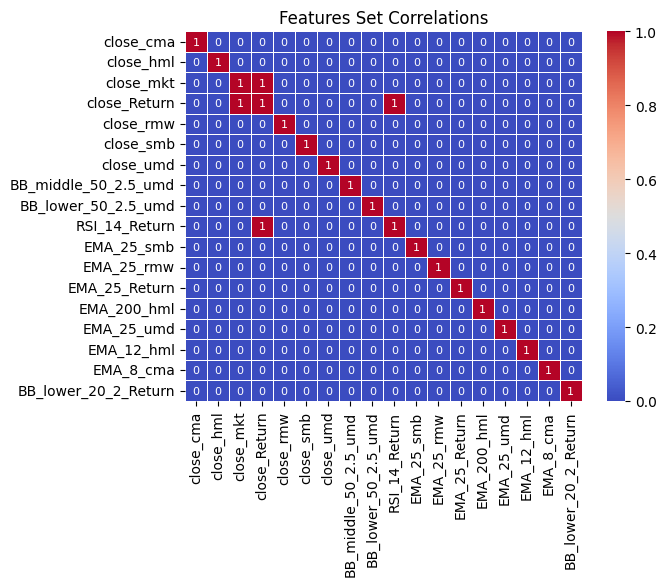

In [60]:
import seaborn as sns
df = X_train

# Show pairs with very high correlation
sns.heatmap(df.corr()>0.8,
annot=True,
annot_kws={"size": 8},
linewidth=.5,
cmap="coolwarm",
cbar=True);

plt.title('Features Set Correlations');

### Feature Importance

In [61]:
# Base estimator
est = RandomForestClassifier()
est.fit(X_train, y_train)

RandomForestClassifier()

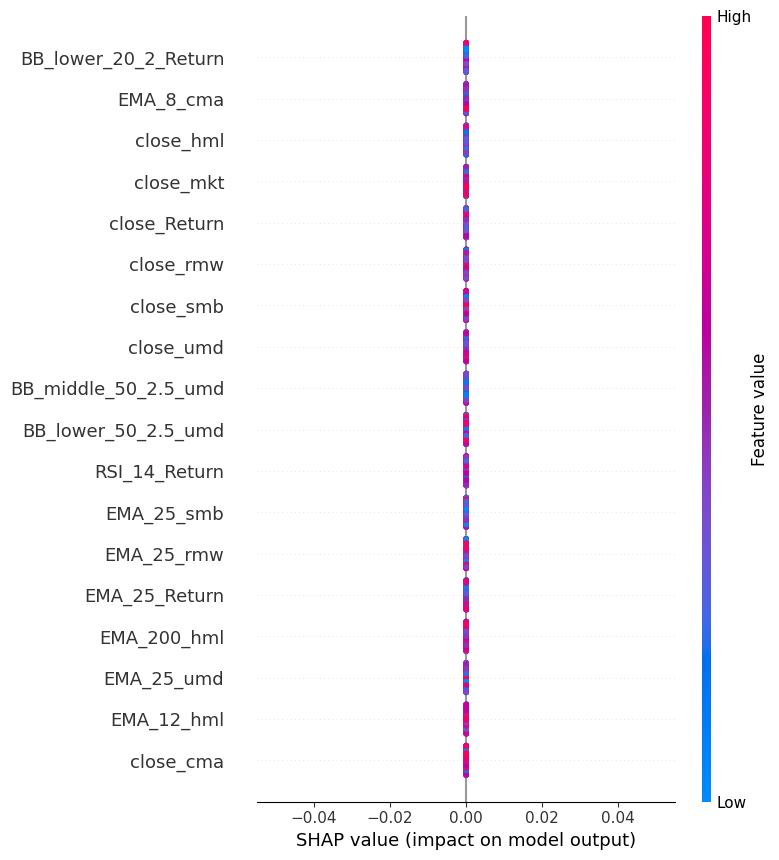

In [62]:
# Determine SHAP values
import shap

explainer = shap.TreeExplainer(est)
shap_values = explainer.shap_values(X_train)

# Interpretation plot
shap.summary_plot(shap_values, X_train)

In [63]:
# EDA on the final input matrix
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
close_cma,600.0,-1.184238e-17,1.000834,-3.830998,-0.609815,0.017945,0.616419,3.416566
close_hml,600.0,1.184238e-17,1.000834,-3.744837,-0.588540,-0.070575,0.580431,4.334948
close_mkt,600.0,1.776357e-17,1.000834,-5.547969,-0.519378,0.019665,0.570375,5.369493
close_Return,600.0,0.000000e+00,1.000834,-3.710519,-0.627551,0.051379,0.629432,3.053162
close_rmw,600.0,-5.921189e-18,1.000834,-3.473065,-0.599465,0.015365,0.679707,3.996950
close_smb,600.0,4.440892e-18,1.000834,-4.395884,-0.544593,0.063518,0.621712,4.046302
close_umd,600.0,-1.184238e-17,1.000834,-3.836412,-0.596548,-0.019077,0.629593,4.350155
BB_middle_50_2.5_umd,600.0,-1.184238e-17,1.000834,-1.931984,-0.713199,-0.118372,0.528902,3.336208
BB_lower_50_2.5_umd,600.0,-6.394885e-16,1.000834,-1.726443,-0.759233,-0.066840,0.629898,3.040849
RSI_14_Return,600.0,-5.343873e-16,1.000834,-3.999887,-0.619464,0.066224,0.663267,2.905217
